# 🧠 Del perceptrón a las redes neuronales artificiales
### Apuntes prácticos · Machine Learning (CEIABD)

**Objetivos del notebook**

1. Entender qué es una **neurona artificial** y cómo funciona el **perceptrón**.
2. Comprender por qué necesitamos el **perceptrón multicapa (MLP)** y cómo aprende (*backpropagation*).
3. Tener una visión general de las **redes neuronales artificiales (RNA)**: arquitectura, activaciones, pérdida, optimizador y regularización.
4. Implementar cada idea en **NumPy** (desde cero), **scikit-learn**, **TensorFlow/Keras** y **PyTorch**, viendo las equivalencias entre librerías.
5. Consolidar con **ejercicios guiados**.

**Índice**

0. Preparación del entorno
1. La neurona artificial
2. El perceptrón
3. El perceptrón multicapa (MLP)
4. Redes neuronales artificiales: visión general y ejemplo completo
5. Resumen y chuleta de equivalencias
6. Ejercicios guiados de consolidación
7. Soluciones

> 💡 Todos los conjuntos de datos se generan o vienen incluidos en scikit-learn: no hace falta descargar nada.

## 0. Preparación del entorno

Si alguna librería no está instalada, descomenta la celda siguiente (en Google Colab ya vienen todas).

> ⚠️ **Si el kernel se cae al ejecutar PyTorch después de TensorFlow** (error `LLVM ERROR: inconsistency in registered CommandLine options`), es un choque entre versiones muy recientes de ambas librerías en el mismo entorno. Solución: instala una versión de PyTorch algo anterior (p. ej. `pip install "torch==2.9.1"`) o usa Google Colab. Este notebook se ha probado con TensorFlow 2.21, PyTorch 2.9 y scikit-learn 1.9.

In [1]:
# !pip install numpy matplotlib scikit-learn tensorflow torch

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification, make_moons, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

import tensorflow as tf
from tensorflow import keras

import torch
import torch.nn as nn

# Semillas para que los resultados sean reproducibles
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

print("TensorFlow:", tf.__version__, "| PyTorch:", torch.__version__)

TensorFlow: 2.21.0 | PyTorch: 2.9.1+cu128


Función auxiliar para dibujar la **frontera de decisión** de cualquier modelo en 2D. La usaremos muchas veces.

In [3]:
def plot_frontera(predict_fn, X, y, titulo="", ax=None):
    # predict_fn: función que recibe un array (n, 2) y devuelve la clase predicha (0/1)
    ax = ax or plt.gca()
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = predict_fn(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=40)
    ax.set_title(titulo)

## 1. La neurona artificial

Una neurona artificial es una **función matemática muy simple** inspirada (de lejos) en la neurona biológica:

| Neurona biológica | Neurona artificial |
|---|---|
| Dendritas (reciben señales) | Entradas $x_1, \dots, x_n$ |
| Fuerza de la sinapsis | Pesos $w_1, \dots, w_n$ |
| Umbral de disparo | Sesgo (*bias*) $b$ |
| Soma: acumula y decide si "dispara" | Suma ponderada + **función de activación** $f$ |
| Axón (salida) | Salida $\hat{y}$ |

Funciona en dos pasos:

$$
z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}\cdot\mathbf{x} + b
\qquad\qquad
\hat{y} = f(z)
$$

- Los **pesos** indican cuánto importa cada entrada (positivos excitan, negativos inhiben).
- El **sesgo** desplaza el umbral a partir del cual la neurona se activa.
- La **función de activación** introduce **no linealidad**. Sin ella, apilar neuronas equivaldría a una sola operación lineal y la red no ganaría potencia.

### Funciones de activación más comunes

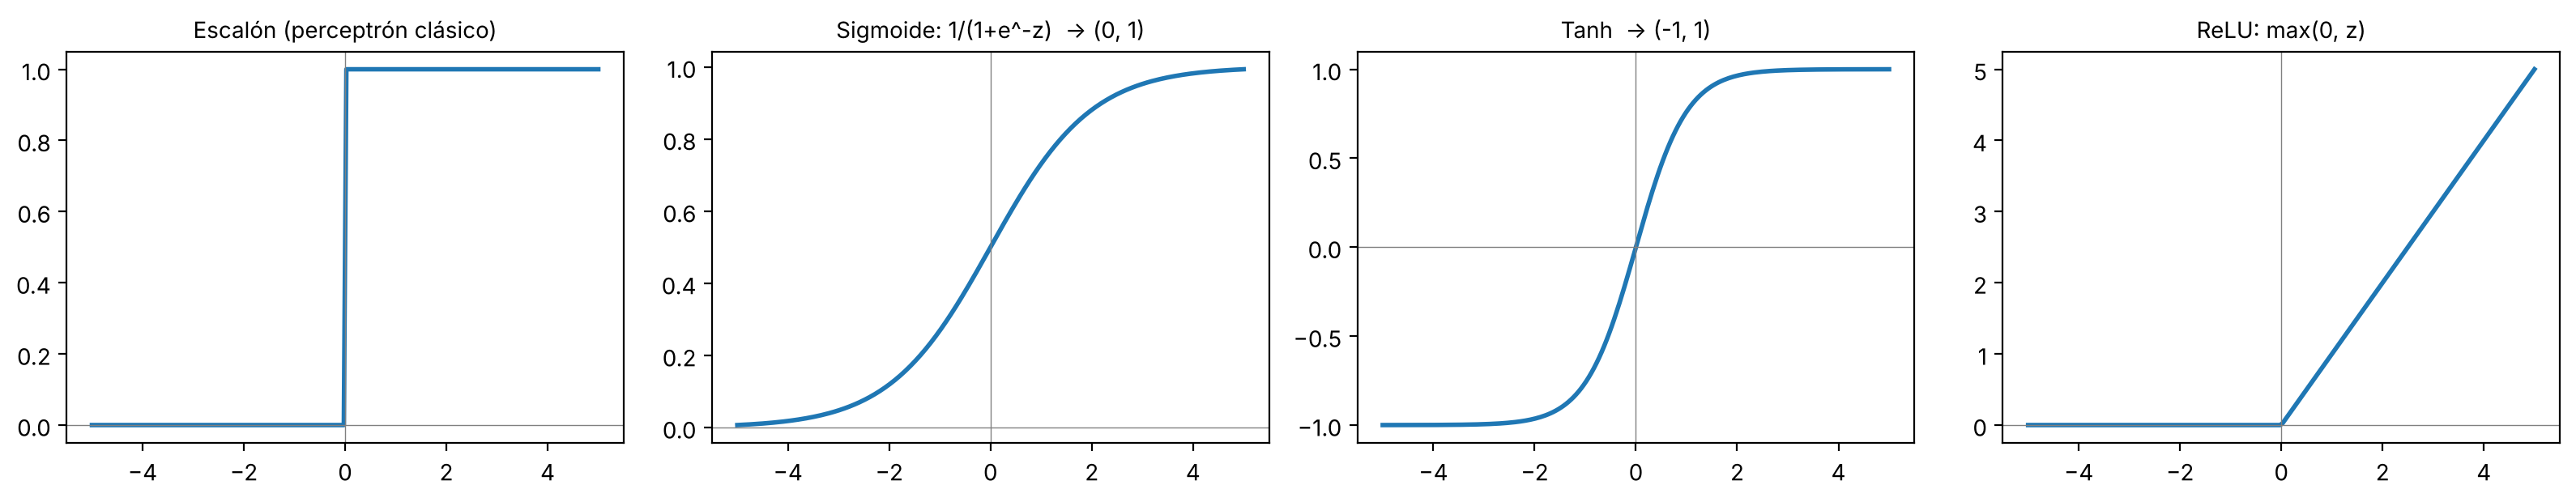

In [4]:
z = np.linspace(-5, 5, 200)
activaciones = {
    "Escalón (perceptrón clásico)": np.where(z >= 0, 1, 0),
    "Sigmoide: 1/(1+e^-z)  → (0, 1)": 1 / (1 + np.exp(-z)),
    "Tanh  → (-1, 1)": np.tanh(z),
    "ReLU: max(0, z)": np.maximum(0, z),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, (nombre, valores) in zip(axes, activaciones.items()):
    ax.plot(z, valores, lw=2)
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5)
    ax.set_title(nombre, fontsize=10)
plt.tight_layout(); plt.show()

| Activación | Uso típico |
|---|---|
| **Escalón** | Perceptrón original de Rosenblatt (no es derivable → no sirve para *backpropagation*). |
| **Sigmoide** | Capa de salida en clasificación **binaria** (devuelve una probabilidad). |
| **Tanh** | Capas ocultas en redes antiguas / recurrentes. |
| **ReLU** | **Opción por defecto en capas ocultas** hoy en día: simple y entrena rápido. |
| **Softmax** | Capa de salida en clasificación **multiclase** (las salidas suman 1). |

Calculemos a mano la salida de una neurona:

In [5]:
x = np.array([1.0, 0.5, -1.0])   # entradas
w = np.array([0.4, -0.2, 0.3])   # pesos
b = 0.1                          # sesgo

z = np.dot(w, x) + b
print(f"z = {z:.2f}")
print("Salida con escalón :", int(z >= 0))
print(f"Salida con sigmoide: {1 / (1 + np.exp(-z)):.3f}")

z = 0.10
Salida con escalón : 1
Salida con sigmoide: 0.525


## 2. El perceptrón

### 2.1 Teoría

El **perceptrón** (Frank Rosenblatt, 1958) es la red neuronal más sencilla: **una sola neurona** con función **escalón**. Sirve para **clasificación binaria**:

$$
\hat{y} = \begin{cases} 1 & \text{si } \mathbf{w}\cdot\mathbf{x} + b \ge 0 \\ 0 & \text{en otro caso} \end{cases}
$$

Geométricamente, la ecuación $\mathbf{w}\cdot\mathbf{x} + b = 0$ es una **recta** (en 2D), un plano (en 3D) o un hiperplano (en general). El perceptrón **divide el espacio en dos mitades**: es un **clasificador lineal**.

**Regla de aprendizaje del perceptrón** (regla delta). Para cada ejemplo $(\mathbf{x}, y)$:

$$
\text{error} = y - \hat{y} \qquad
w_i \leftarrow w_i + \eta \cdot \text{error} \cdot x_i \qquad
b \leftarrow b + \eta \cdot \text{error}
$$

- Si acierta, el error es 0 y **no cambia nada**.
- Si se equivoca, mueve los pesos en la dirección que corrige el fallo.
- $\eta$ (*learning rate*) controla el tamaño del paso.
- Se repite sobre todo el dataset durante varias **épocas**.

**Teorema de convergencia:** si los datos son **linealmente separables**, el perceptrón siempre encuentra una recta que los separa. Si no lo son, **nunca converge**.

### 2.2 Perceptrón desde cero con NumPy

Implementarlo una vez a mano ayuda a ver que no hay "magia":

In [6]:
class PerceptronNumPy:
    def __init__(self, lr=0.1, epocas=20):
        self.lr = lr
        self.epocas = epocas

    def predict(self, X):
        return np.where(X @ self.w + self.b >= 0, 1, 0)

    def fit(self, X, y):
        self.w = np.zeros(X.shape[1])
        self.b = 0.0
        self.errores_por_epoca = []
        for _ in range(self.epocas):
            errores = 0
            for xi, yi in zip(X, y):
                error = yi - self.predict(xi)
                self.w += self.lr * error * xi      # regla delta
                self.b += self.lr * error
                errores += int(error != 0)
            self.errores_por_epoca.append(errores)
        return self

Probamos con las puertas lógicas **AND** y **OR**, que son linealmente separables:

AND: pesos=[0.2 0.1], sesgo=-0.2, predicciones=[0 0 0 1], errores por época=[2, 3, 3, 0, 0, 0, 0, 0, 0, 0]
OR: pesos=[0.1 0.1], sesgo=-0.1, predicciones=[0 1 1 1], errores por época=[2, 2, 1, 0, 0, 0, 0, 0, 0, 0]


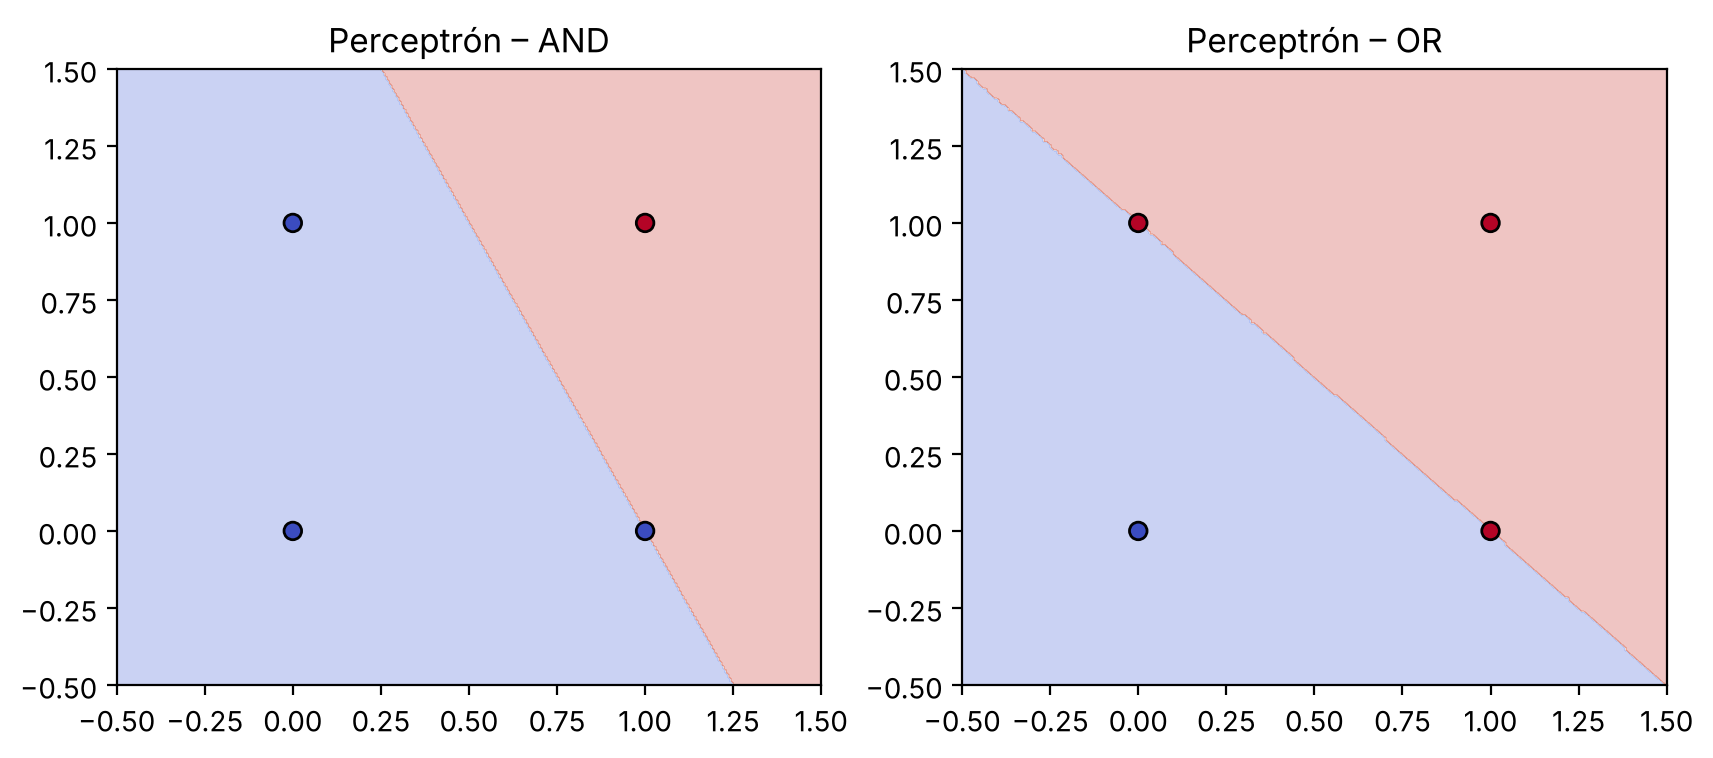

In [7]:
X_logica = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])
y_or  = np.array([0, 1, 1, 1])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, y_puerta) in zip(axes, [("AND", y_and), ("OR", y_or)]):
    p = PerceptronNumPy(lr=0.1, epocas=10).fit(X_logica, y_puerta)
    print(f"{nombre}: pesos={p.w}, sesgo={p.b:.1f}, predicciones={p.predict(X_logica)}, "
          f"errores por época={p.errores_por_epoca}")
    plot_frontera(p.predict, X_logica, y_puerta, f"Perceptrón – {nombre}", ax)
plt.show()

### 2.3 La gran limitación: el problema XOR

La puerta **XOR** (sale 1 solo si las entradas son distintas) **no es linealmente separable**: no existe ninguna recta que separe los 1 de los 0. Minsky y Papert lo señalaron en 1969 y frenó la investigación en redes neuronales durante años.

Predicciones: [1 1 0 0]  Real: [0 1 1 0]
Errores en las últimas épocas: [4, 4, 4, 4, 4] → nunca llega a 0


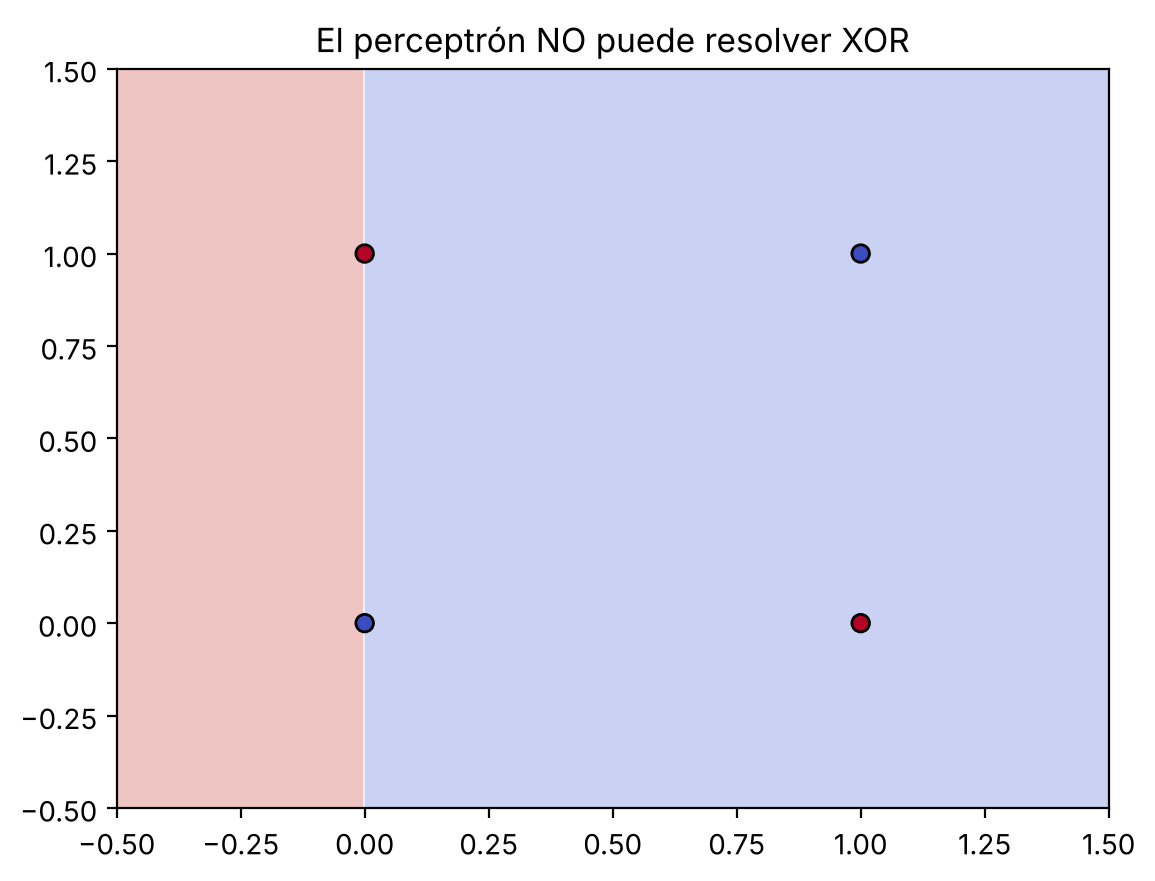

In [8]:
y_xor = np.array([0, 1, 1, 0])
p_xor = PerceptronNumPy(lr=0.1, epocas=50).fit(X_logica, y_xor)
print("Predicciones:", p_xor.predict(X_logica), " Real:", y_xor)
print("Errores en las últimas épocas:", p_xor.errores_por_epoca[-5:], "→ nunca llega a 0")
plot_frontera(p_xor.predict, X_logica, y_xor, "El perceptrón NO puede resolver XOR")
plt.show()

La solución llegará en la sección 3 con el **perceptrón multicapa**.

### 2.4 Perceptrón con scikit-learn

scikit-learn incluye `Perceptron`, que implementa exactamente esta idea. Lo usamos sobre un dataset sintético de dos clases:

Pesos: [[0.32572677 0.77682862]]  Sesgo: [-0.1]
Accuracy en test: 0.960


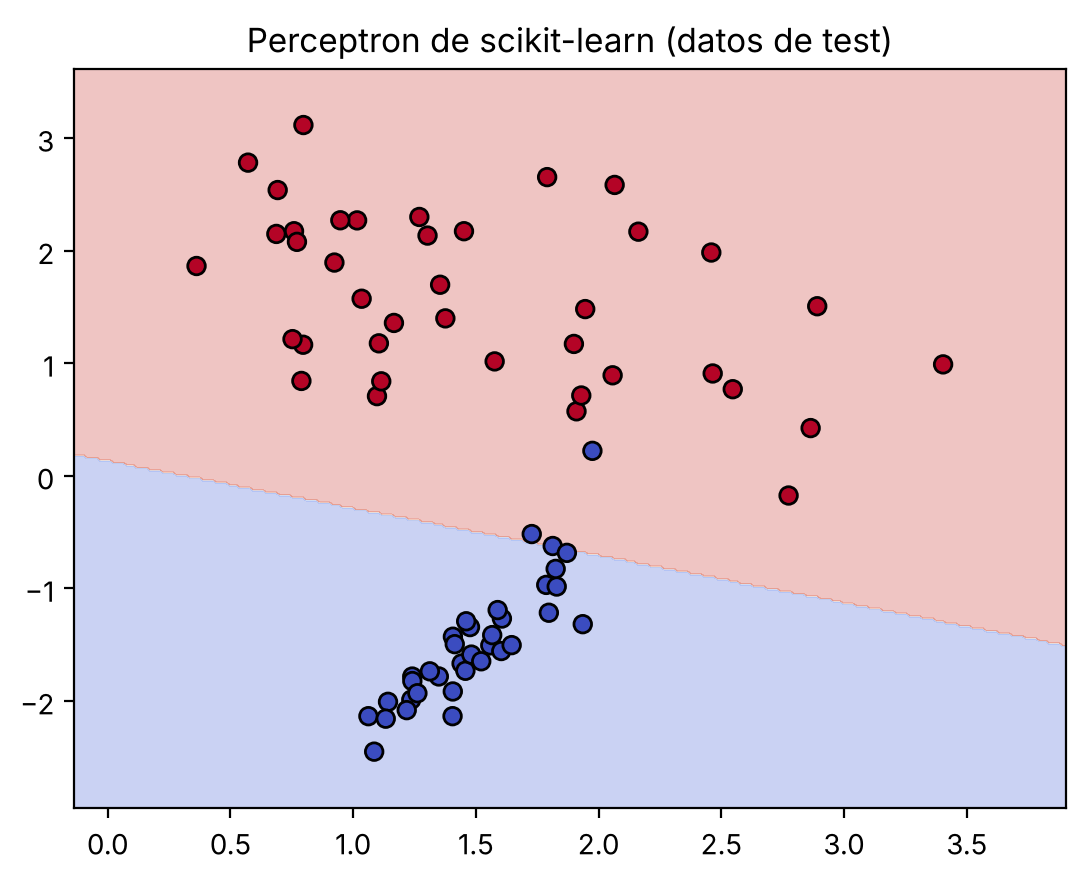

In [9]:
from sklearn.linear_model import Perceptron

X, y = make_classification(n_samples=300, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, class_sep=1.5, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)

perc_sk = Perceptron(eta0=0.1, max_iter=100, random_state=SEED)
perc_sk.fit(X_train, y_train)

print("Pesos:", perc_sk.coef_, " Sesgo:", perc_sk.intercept_)
print(f"Accuracy en test: {perc_sk.score(X_test, y_test):.3f}")
plot_frontera(perc_sk.predict, X_test, y_test, "Perceptron de scikit-learn (datos de test)")
plt.show()

### 2.5 El "perceptrón" en Keras y en PyTorch

Las librerías de *deep learning* no traen un perceptrón con función escalón, porque el escalón **no es derivable** y estas librerías entrenan por **descenso del gradiente**. El equivalente moderno es **una sola neurona con activación sigmoide** (que, matemáticamente, es una **regresión logística**). La frontera de decisión sigue siendo una recta.

**Keras** (TensorFlow): modelo `Sequential` con una capa `Dense` de 1 neurona.

In [10]:
modelo_keras_1n = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(1, activation="sigmoid"),   # 1 neurona = 2 pesos + 1 sesgo
])
modelo_keras_1n.compile(optimizer=keras.optimizers.SGD(learning_rate=0.1),
                        loss="binary_crossentropy", metrics=["accuracy"])
modelo_keras_1n.summary()

modelo_keras_1n.fit(X_train, y_train, epochs=50, verbose=0)
loss, acc = modelo_keras_1n.evaluate(X_test, y_test, verbose=0)
print(f"Accuracy en test (Keras): {acc:.3f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             3 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3 (12.00 B)

 Trainable params: 3 (12.00 B)

 Non-trainable params: 0 (0.00 B)

Accuracy en test (Keras): 0.987


**PyTorch**: definimos la capa `nn.Linear(2, 1)` y escribimos nosotros el **bucle de entrenamiento**. Es más código, pero se ve claramente cada paso:

1. *Forward*: calcular la predicción.
2. Calcular la **pérdida**.
3. `zero_grad()`: borrar gradientes anteriores.
4. `backward()`: calcular gradientes.
5. `step()`: actualizar pesos.

In [11]:
# Los datos deben ser tensores float32
Xtr_t = torch.tensor(X_train, dtype=torch.float32)
ytr_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)   # forma (n, 1)
Xte_t = torch.tensor(X_test, dtype=torch.float32)

modelo_torch_1n = nn.Linear(2, 1)           # z = w·x + b
criterio = nn.BCEWithLogitsLoss()           # sigmoide + binary cross-entropy en uno
optimizador = torch.optim.SGD(modelo_torch_1n.parameters(), lr=0.1)

for epoca in range(200):
    logits = modelo_torch_1n(Xtr_t)         # 1. forward
    perdida = criterio(logits, ytr_t)       # 2. pérdida
    optimizador.zero_grad()                 # 3. reiniciar gradientes
    perdida.backward()                      # 4. backpropagation
    optimizador.step()                      # 5. actualizar pesos

with torch.no_grad():
    pred = (torch.sigmoid(modelo_torch_1n(Xte_t)) >= 0.5).int().numpy().ravel()
print(f"Accuracy en test (PyTorch): {accuracy_score(y_test, pred):.3f}")
print("Pesos:", modelo_torch_1n.weight.data.numpy(), " Sesgo:", modelo_torch_1n.bias.data.numpy())

Accuracy en test (PyTorch): 0.987
Pesos: [[0.3308721 2.493077 ]]  Sesgo: [-0.30655494]


## 3. El perceptrón multicapa (MLP)

### 3.1 Teoría

Si una neurona solo traza **una recta**, la idea es **combinar varias**: unas neuronas trazan rectas distintas y otras combinan sus resultados. Así nace el **perceptrón multicapa** (*Multi-Layer Perceptron*, MLP):

```
 Capa de entrada      Capa(s) oculta(s)        Capa de salida
   x1 ──┐          ┌──( h1 )──┐
        ├──────────┼──( h2 )──┼──────────(  ŷ  )
   x2 ──┘          └──( h3 )──┘
```

- **Capa de entrada**: no calcula nada, solo recibe los datos (una "neurona" por característica).
- **Capas ocultas**: neuronas con activación **no lineal** (normalmente ReLU). Aprenden **representaciones intermedias**.
- **Capa de salida**: depende del problema (ver tabla en la sección 4).
- Es una red **densa** o *fully connected*: cada neurona se conecta con todas las de la capa siguiente.
- **Teorema de aproximación universal:** un MLP con al menos una capa oculta y suficientes neuronas puede aproximar cualquier función continua.

### 3.2 ¿Cómo aprende? *Forward*, pérdida y *backpropagation*

1. **Propagación hacia delante (*forward*)**: los datos atraviesan la red capa a capa y se obtiene $\hat{y}$.
2. **Función de pérdida**: mide lo lejos que está $\hat{y}$ de $y$ (p. ej. *binary cross-entropy* o error cuadrático medio).
3. **Retropropagación (*backpropagation*, Rumelhart, Hinton y Williams, 1986)**: con la regla de la cadena se calcula cuánto contribuye **cada peso** al error, empezando por la salida y retrocediendo hasta la entrada.
4. **Descenso del gradiente**: cada peso se mueve un poco en la dirección que reduce la pérdida:
$$ w \leftarrow w - \eta \, \frac{\partial \, \text{pérdida}}{\partial w} $$
5. Se repite durante muchas **épocas**, normalmente en **mini-lotes** (*batches*) de ejemplos.

Esto exige activaciones **derivables**: por eso se sustituye el escalón por sigmoide, tanh o ReLU.

### 3.3 MLP desde cero: resolviendo XOR

Una capa oculta de 4 neuronas basta para resolver XOR. Escribimos el *forward* y el *backward* a mano:

Salidas de la red: [0.015 0.975 0.977 0.03 ]
Predicción       : [0 1 1 0]  Real: [0 1 1 0]


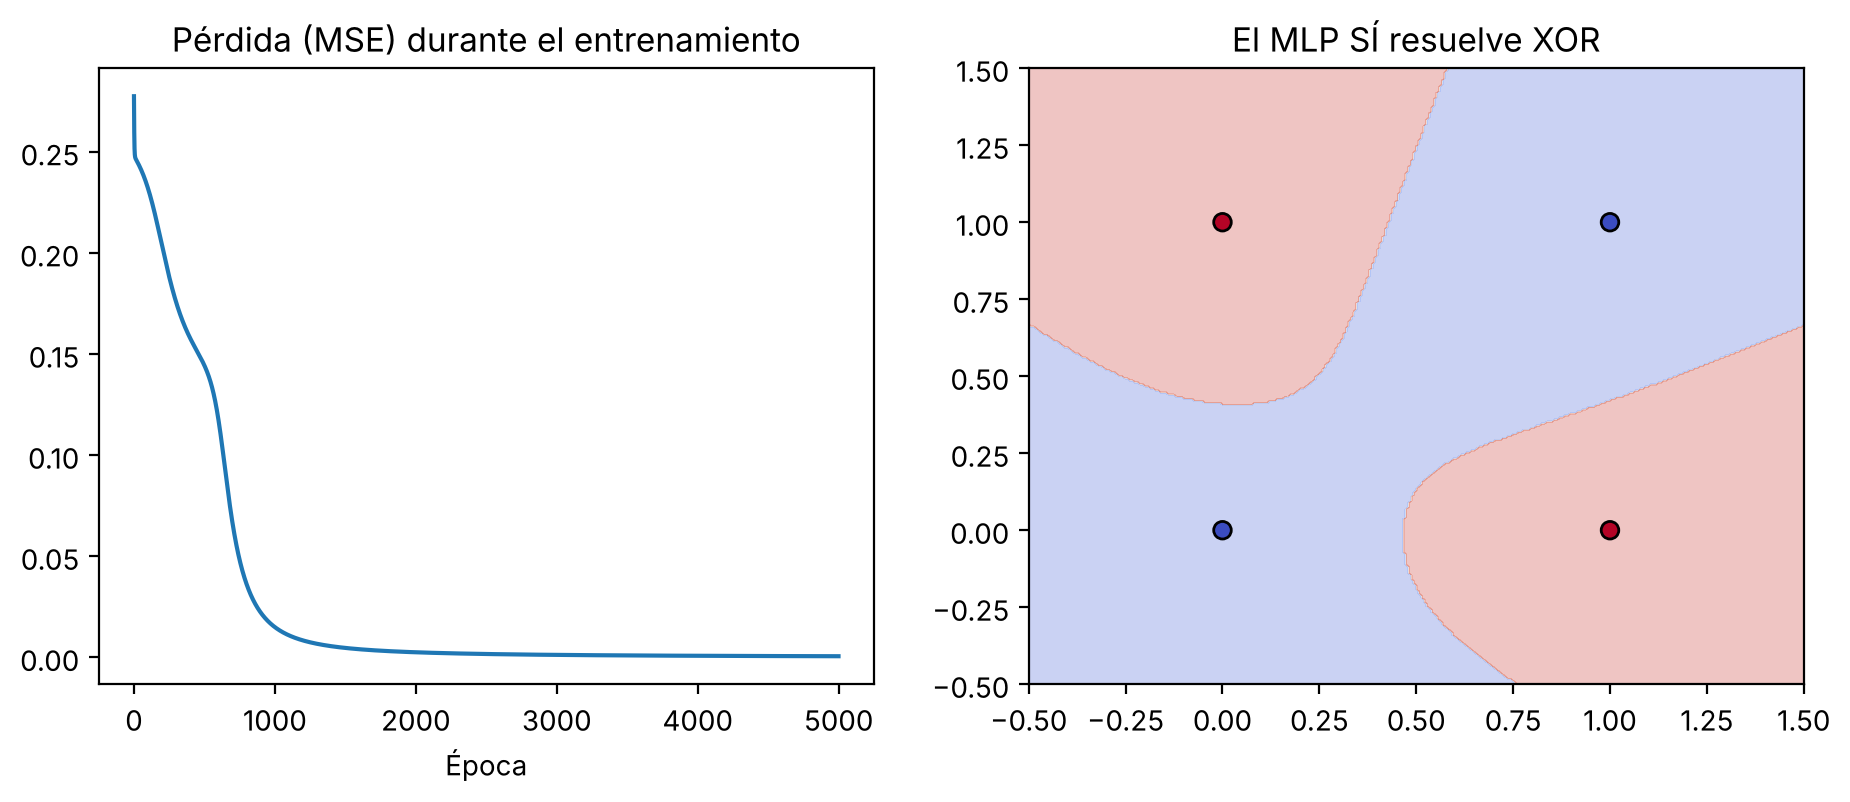

In [12]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

rng = np.random.default_rng(SEED)
X_xor = X_logica.astype(float)
Y_xor = y_xor.reshape(-1, 1).astype(float)

# Arquitectura 2 → 4 → 1
W1 = rng.normal(0, 1, (2, 4)); b1 = np.zeros((1, 4))
W2 = rng.normal(0, 1, (4, 1)); b2 = np.zeros((1, 1))
lr = 0.5
historial = []

for epoca in range(5000):
    # ---- forward
    A1 = sigmoide(X_xor @ W1 + b1)       # salida capa oculta
    A2 = sigmoide(A1 @ W2 + b2)          # salida de la red
    historial.append(np.mean((Y_xor - A2) ** 2))

    # ---- backward (regla de la cadena)
    d2 = (A2 - Y_xor) * A2 * (1 - A2)    # error en la salida
    d1 = (d2 @ W2.T) * A1 * (1 - A1)     # error retropropagado a la capa oculta

    # ---- actualización (descenso del gradiente)
    W2 -= lr * A1.T @ d2;  b2 -= lr * d2.sum(axis=0, keepdims=True)
    W1 -= lr * X_xor.T @ d1; b1 -= lr * d1.sum(axis=0, keepdims=True)

print("Salidas de la red:", A2.ravel().round(3))
print("Predicción       :", (A2.ravel() >= 0.5).astype(int), " Real:", y_xor)

predict_xor = lambda X: (sigmoide(sigmoide(X @ W1 + b1) @ W2 + b2) >= 0.5).astype(int).ravel()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(historial); axes[0].set_title("Pérdida (MSE) durante el entrenamiento"); axes[0].set_xlabel("Época")
plot_frontera(predict_xor, X_logica, y_xor, "El MLP SÍ resuelve XOR", axes[1])
plt.show()

> 🔑 La frontera ya **no es una recta**: la capa oculta ha creado una representación en la que XOR sí es separable.

En la práctica nunca se escribe el *backward* a mano: las librerías lo calculan automáticamente. Usaremos el dataset `make_moons` (dos medias lunas entrelazadas), que no es linealmente separable.

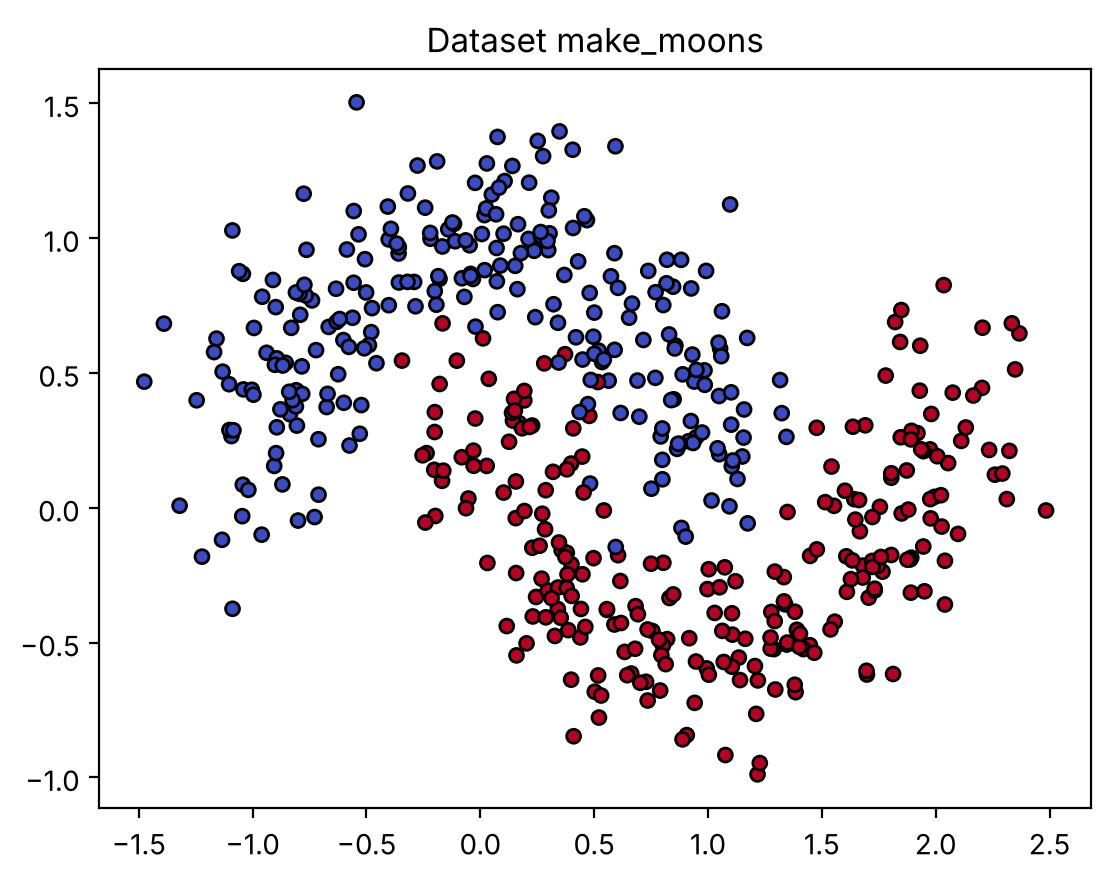

In [13]:
X, y = make_moons(n_samples=500, noise=0.2, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)

# Las redes neuronales funcionan mucho mejor con datos estandarizados (media 0, desviación 1)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k", s=25)
plt.title("Dataset make_moons"); plt.show()

### 3.4 MLP con scikit-learn: `MLPClassifier`

La forma más rápida. `hidden_layer_sizes=(16, 8)` significa **dos capas ocultas** de 16 y 8 neuronas.

Accuracy en test (scikit-learn MLP): 0.976
Accuracy en test (Perceptron lineal): 0.824


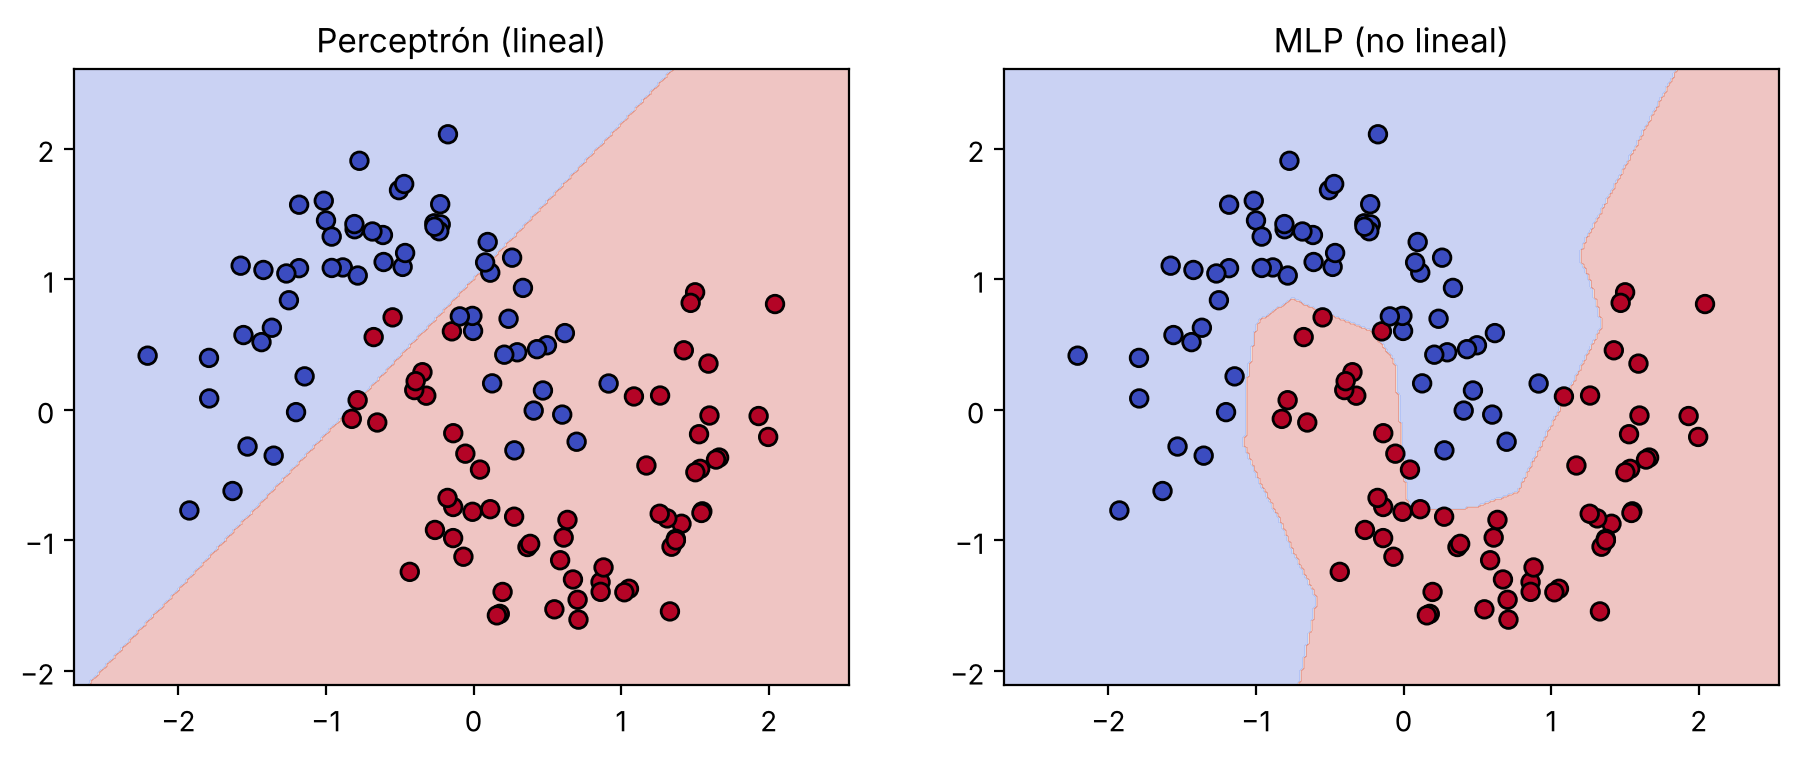

In [14]:
from sklearn.neural_network import MLPClassifier

mlp_sk = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                       learning_rate_init=0.01, max_iter=500, random_state=SEED)
mlp_sk.fit(X_train_s, y_train)
print(f"Accuracy en test (scikit-learn MLP): {mlp_sk.score(X_test_s, y_test):.3f}")

# Comparación con el perceptrón lineal
perc = Perceptron(random_state=SEED).fit(X_train_s, y_train)
print(f"Accuracy en test (Perceptron lineal): {perc.score(X_test_s, y_test):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_frontera(perc.predict, X_test_s, y_test, "Perceptrón (lineal)", axes[0])
plot_frontera(mlp_sk.predict, X_test_s, y_test, "MLP (no lineal)", axes[1])
plt.show()

### 3.5 MLP con TensorFlow / Keras

La misma arquitectura `2 → 16 → 8 → 1`. En Keras hay tres pasos: **definir** (`Sequential`), **compilar** (`compile`) y **entrenar** (`fit`).

In [15]:
mlp_keras = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
mlp_keras.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01),
                  loss="binary_crossentropy", metrics=["accuracy"])
mlp_keras.summary()

hist = mlp_keras.fit(X_train_s, y_train, epochs=100, batch_size=32,
                     validation_split=0.2, verbose=0)
print(f"Accuracy en test (Keras MLP): {mlp_keras.evaluate(X_test_s, y_test, verbose=0)[1]:.3f}")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193 (772.00 B)

 Trainable params: 193 (772.00 B)

 Non-trainable params: 0 (0.00 B)

Accuracy en test (Keras MLP): 0.976


> 🧮 **Contar parámetros:** una capa `Dense` con $n_{in}$ entradas y $n_{out}$ neuronas tiene $n_{in}\cdot n_{out} + n_{out}$ parámetros. Aquí: $2\cdot16+16=48$, $16\cdot8+8=136$, $8\cdot1+1=9$ → **193** en total.

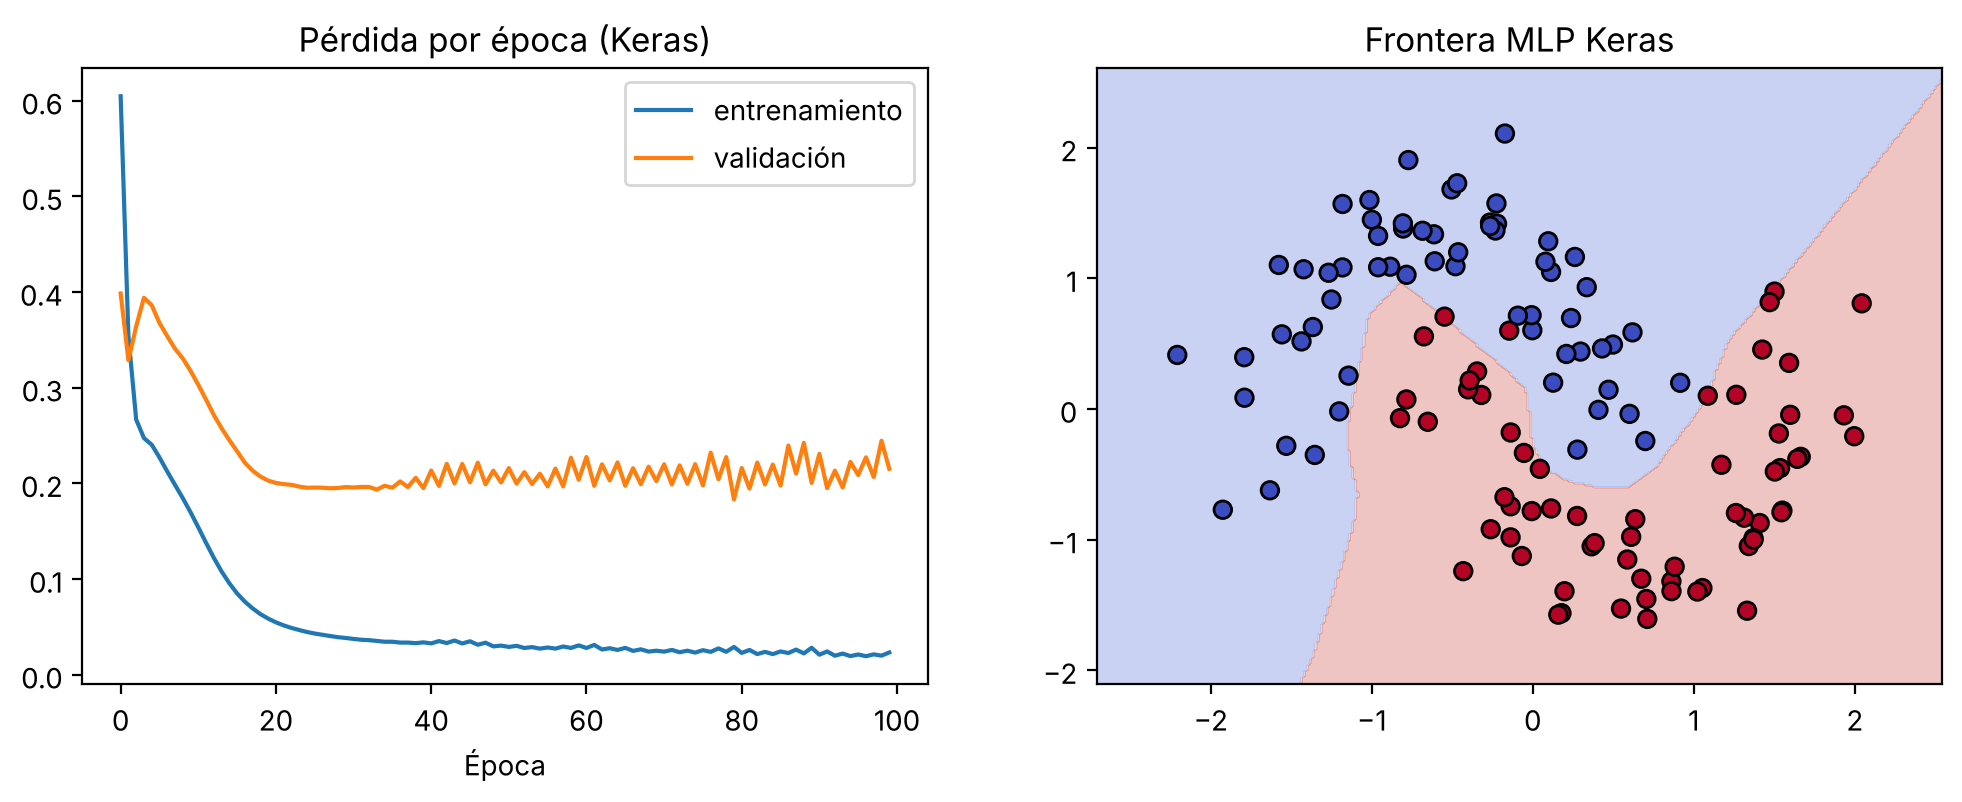

In [16]:
predict_keras = lambda X: (mlp_keras.predict(X, verbose=0) >= 0.5).astype(int).ravel()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist.history["loss"], label="entrenamiento")
axes[0].plot(hist.history["val_loss"], label="validación")
axes[0].set_title("Pérdida por época (Keras)"); axes[0].set_xlabel("Época"); axes[0].legend()
plot_frontera(predict_keras, X_test_s, y_test, "Frontera MLP Keras", axes[1])
plt.show()

### 3.6 MLP con PyTorch

En PyTorch se define la red con `nn.Sequential` (o una clase que hereda de `nn.Module`) y se entrena con un bucle explícito por **mini-lotes** usando `DataLoader`.

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
)
Parámetros: 193


Accuracy en test (PyTorch MLP): 0.984


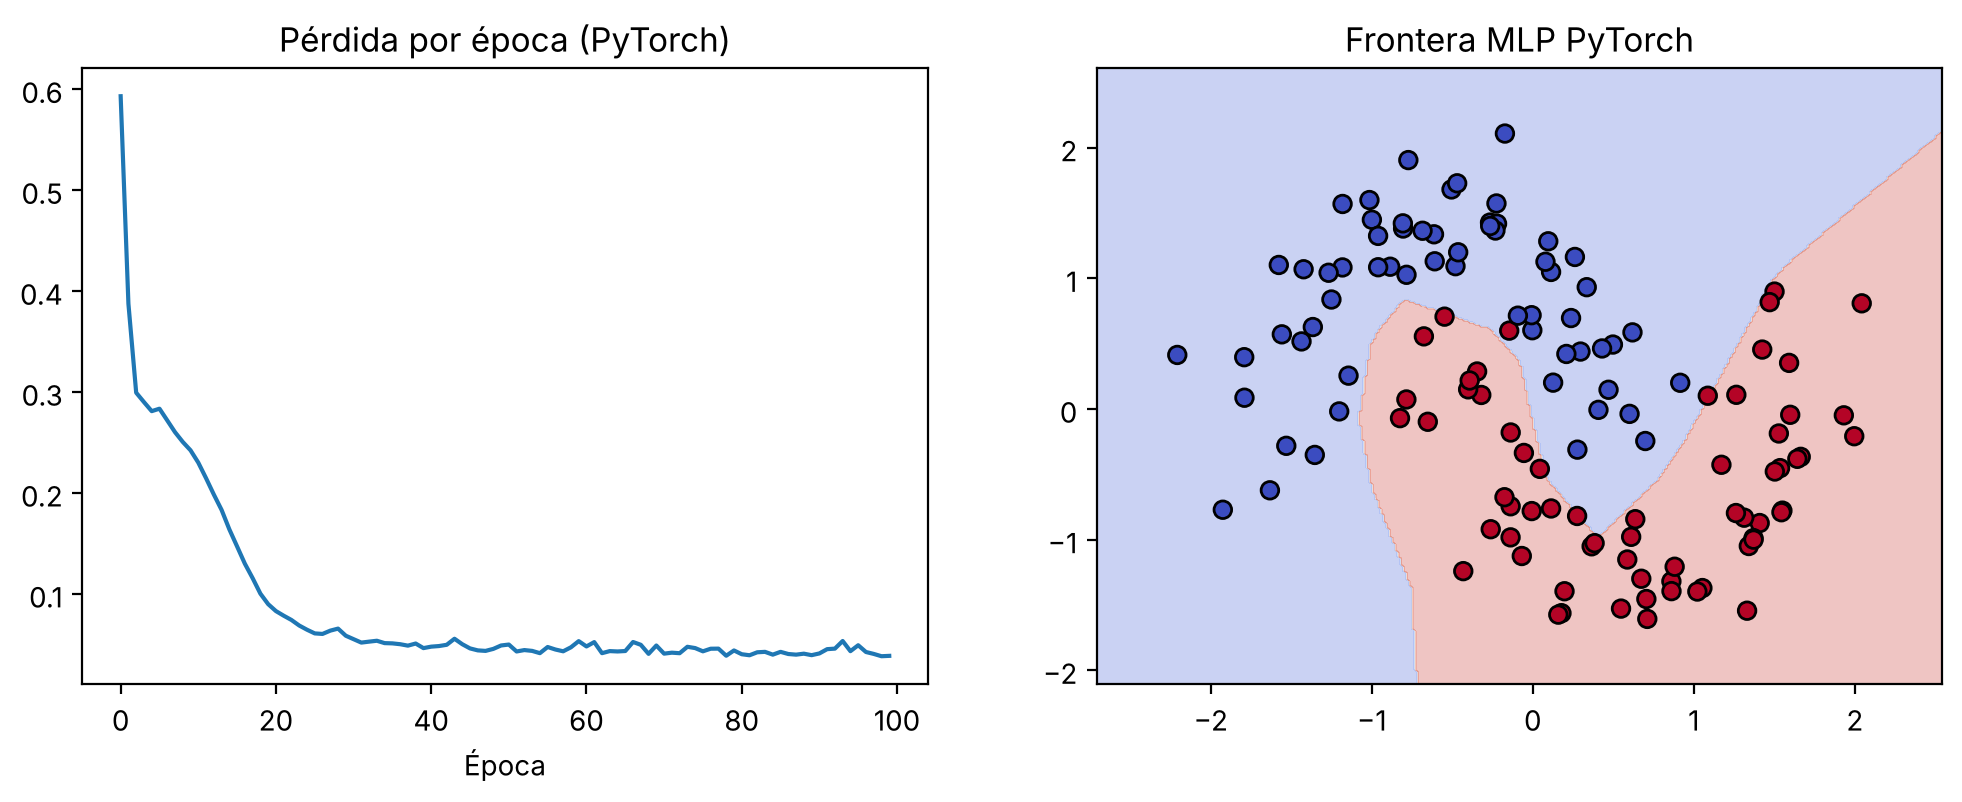

In [17]:
from torch.utils.data import TensorDataset, DataLoader

mlp_torch = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),
    nn.Linear(16, 8), nn.ReLU(),
    nn.Linear(8, 1),            # sin sigmoide: la incluye BCEWithLogitsLoss
)
print(mlp_torch)
print("Parámetros:", sum(p.numel() for p in mlp_torch.parameters()))

dataset = TensorDataset(torch.tensor(X_train_s, dtype=torch.float32),
                        torch.tensor(y_train, dtype=torch.float32).unsqueeze(1))
loader = DataLoader(dataset, batch_size=32, shuffle=True)

criterio = nn.BCEWithLogitsLoss()
optimizador = torch.optim.Adam(mlp_torch.parameters(), lr=0.01)

perdidas = []
for epoca in range(100):
    mlp_torch.train()
    total = 0.0
    for xb, yb in loader:
        perdida = criterio(mlp_torch(xb), yb)
        optimizador.zero_grad()
        perdida.backward()
        optimizador.step()
        total += perdida.item() * len(xb)
    perdidas.append(total / len(dataset))

def predict_torch(X):
    mlp_torch.eval()
    with torch.no_grad():
        logits = mlp_torch(torch.tensor(X, dtype=torch.float32))
    return (torch.sigmoid(logits) >= 0.5).int().numpy().ravel()

print(f"Accuracy en test (PyTorch MLP): {accuracy_score(y_test, predict_torch(X_test_s)):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(perdidas); axes[0].set_title("Pérdida por época (PyTorch)"); axes[0].set_xlabel("Época")
plot_frontera(predict_torch, X_test_s, y_test, "Frontera MLP PyTorch", axes[1])
plt.show()

## 4. Redes neuronales artificiales: visión general

### 4.1 ¿Qué es una RNA?

Una **red neuronal artificial** es un modelo formado por **muchas neuronas artificiales organizadas en capas** y conectadas entre sí, cuyos **pesos se ajustan a partir de datos**. El perceptrón (1 neurona) y el MLP (varias capas densas) son los casos más sencillos; cuando una red tiene **muchas capas ocultas** hablamos de **deep learning** (aprendizaje profundo).

### 4.2 Los ingredientes de cualquier red

| Ingrediente | Qué decide | Valores habituales |
|---|---|---|
| **Arquitectura** | Nº de capas y neuronas, tipo de capa | Densa, convolucional, recurrente… |
| **Activación** | No linealidad de cada capa | ReLU en ocultas; sigmoide/softmax/lineal en salida |
| **Función de pérdida** | Qué se minimiza | Ver tabla siguiente |
| **Optimizador** | Cómo se actualizan los pesos | SGD, **Adam** (buen punto de partida) |
| **Learning rate** | Tamaño del paso | 0.001 – 0.01 |
| **Épocas** | Pasadas completas por los datos | Decenas a cientos |
| **Batch size** | Ejemplos por actualización | 16, 32, 64… |

**Capa de salida y pérdida según el problema**

| Problema | Neuronas de salida | Activación de salida | Pérdida |
|---|---|---|---|
| Regresión | 1 (o nº de valores) | Lineal (ninguna) | MSE / MAE |
| Clasificación binaria | 1 | Sigmoide | *Binary cross-entropy* |
| Clasificación multiclase | nº de clases | Softmax | *(Sparse) categorical cross-entropy* |

### 4.3 Tipos de redes (para situarse)

- **Densas / MLP**: datos tabulares. *Las de este notebook.*
- **Convolucionales (CNN)**: imágenes.
- **Recurrentes (RNN, LSTM, GRU)**: secuencias y series temporales.
- **Transformers**: lenguaje natural (base de los LLM), y cada vez más imágenes y audio.

### 4.4 Sobreajuste y regularización

Una red con muchos parámetros puede **memorizar** el conjunto de entrenamiento y generalizar mal (*overfitting*). Señal típica: la pérdida de **entrenamiento baja** pero la de **validación sube**. Remedios habituales:

- **Early stopping**: parar cuando la validación deja de mejorar.
- **Dropout**: apagar al azar un % de neuronas en cada paso de entrenamiento.
- **Regularización L2** (*weight decay*): penalizar pesos grandes.
- Más datos, o una red más pequeña.

### 4.5 Ejemplo completo: clasificar dígitos escritos a mano

Usamos `load_digits` de scikit-learn: 1797 imágenes de 8×8 píxeles (64 características) con dígitos del 0 al 9 → **clasificación multiclase (10 clases)**.

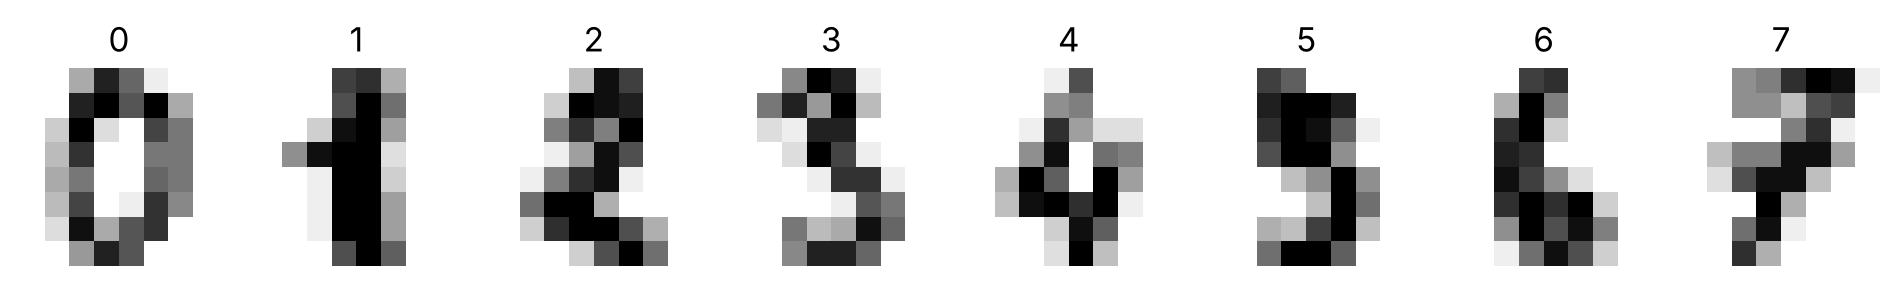

Entrenamiento: (1437, 64)  Test: (360, 64)


In [18]:
digits = load_digits()
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img, etiqueta in zip(axes, digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(etiqueta); ax.axis("off")
plt.show()

X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    stratify=y, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print("Entrenamiento:", X_train_s.shape, " Test:", X_test_s.shape)

**scikit-learn** (con *early stopping* incorporado):

In [19]:
rna_sk = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300,
                       early_stopping=True, random_state=SEED)
rna_sk.fit(X_train_s, y_train)
print(f"Accuracy en test (scikit-learn): {rna_sk.score(X_test_s, y_test):.3f}")

Accuracy en test (scikit-learn): 0.961


**Keras**: salida `softmax` con 10 neuronas, pérdida `sparse_categorical_crossentropy` (las etiquetas son enteros 0–9), `Dropout` y el *callback* `EarlyStopping`.

Se detuvo en la época 35
Accuracy en test (Keras): 0.964


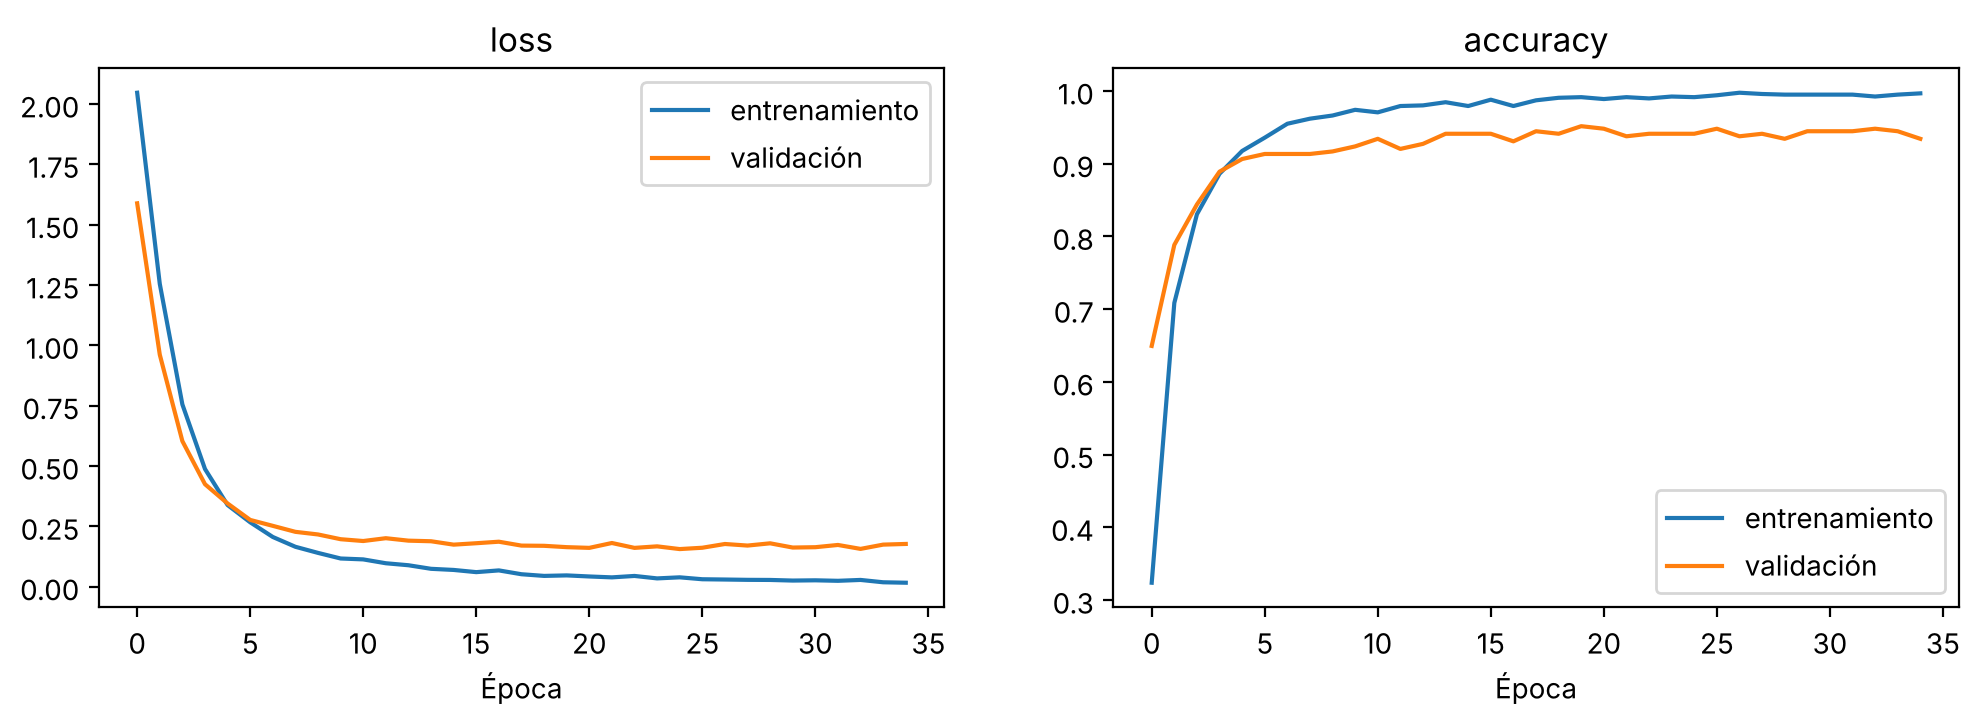

In [20]:
rna_keras = keras.Sequential([
    keras.Input(shape=(64,)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
rna_keras.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
hist = rna_keras.fit(X_train_s, y_train, epochs=200, batch_size=32,
                     validation_split=0.2, callbacks=[parada], verbose=0)
print(f"Se detuvo en la época {len(hist.history['loss'])}")
print(f"Accuracy en test (Keras): {rna_keras.evaluate(X_test_s, y_test, verbose=0)[1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, met in zip(axes, ["loss", "accuracy"]):
    ax.plot(hist.history[met], label="entrenamiento")
    ax.plot(hist.history["val_" + met], label="validación")
    ax.set_title(met); ax.set_xlabel("Época"); ax.legend()
plt.show()

**PyTorch**: definimos la red como **clase** (la forma más habitual en proyectos reales). La salida son 10 *logits*; `nn.CrossEntropyLoss` aplica internamente el *softmax*.

In [21]:
class RedDigitos(nn.Module):
    def __init__(self):
        super().__init__()
        self.capas = nn.Sequential(
            nn.Linear(64, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, 10),
        )
    def forward(self, x):
        return self.capas(x)

rna_torch = RedDigitos()
loader = DataLoader(TensorDataset(torch.tensor(X_train_s, dtype=torch.float32),
                                  torch.tensor(y_train, dtype=torch.long)),   # etiquetas enteras
                    batch_size=32, shuffle=True)
criterio = nn.CrossEntropyLoss()
optimizador = torch.optim.Adam(rna_torch.parameters(), lr=0.001)

for epoca in range(50):
    rna_torch.train()                 # activa Dropout
    for xb, yb in loader:
        perdida = criterio(rna_torch(xb), yb)
        optimizador.zero_grad(); perdida.backward(); optimizador.step()

rna_torch.eval()                      # desactiva Dropout para predecir
with torch.no_grad():
    pred = rna_torch(torch.tensor(X_test_s, dtype=torch.float32)).argmax(dim=1).numpy()
print(f"Accuracy en test (PyTorch): {accuracy_score(y_test, pred):.3f}")

Accuracy en test (PyTorch): 0.983


Veamos dónde se equivoca la red con una **matriz de confusión**:

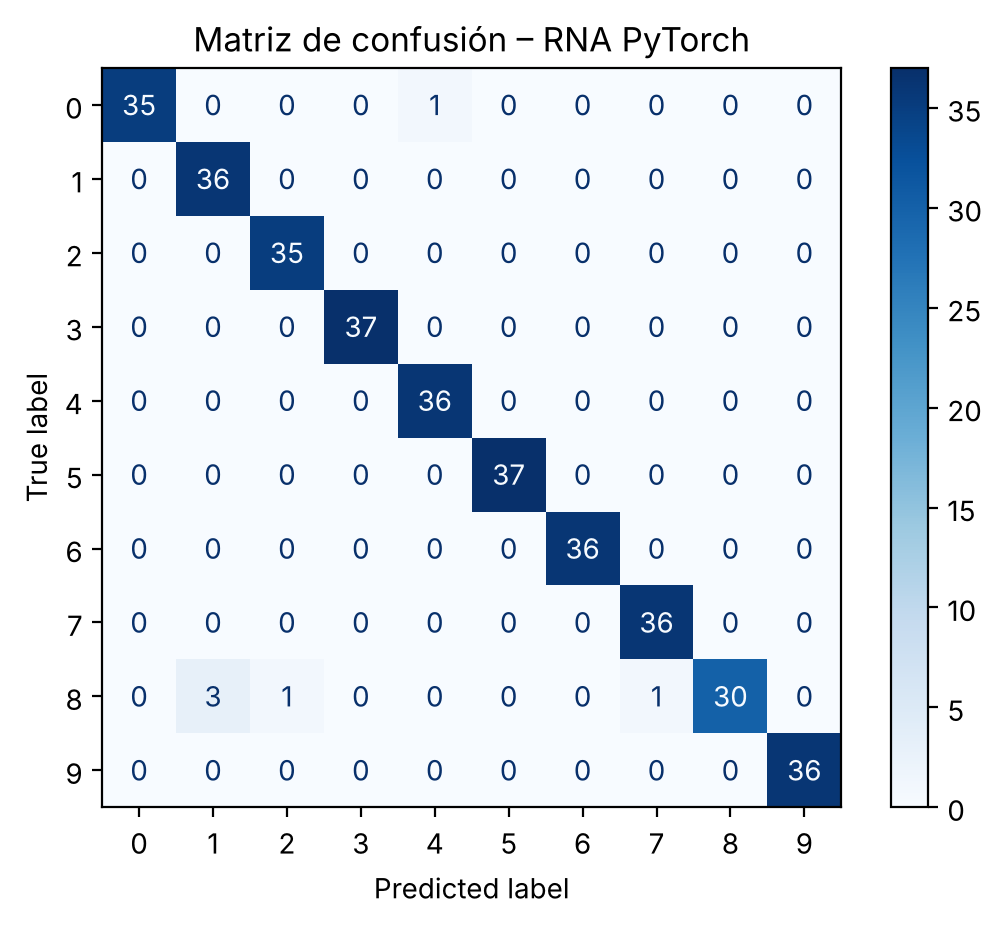

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues")
plt.title("Matriz de confusión – RNA PyTorch"); plt.show()

## 5. Resumen y chuleta de equivalencias

**Ideas clave**

- Una **neurona** calcula $f(\mathbf{w}\cdot\mathbf{x}+b)$.
- El **perceptrón** es una sola neurona con escalón → clasificador **lineal**. No resuelve XOR.
- El **MLP** añade **capas ocultas no lineales** → fronteras de cualquier forma. Se entrena con **backpropagation + descenso del gradiente**.
- Una **RNA** se define por: arquitectura, activaciones, pérdida, optimizador y su entrenamiento (épocas, batch, learning rate). Hay que vigilar el **sobreajuste**.
- **Estandariza** siempre los datos antes de entrenar una red.

**Equivalencias entre librerías**

| Concepto | scikit-learn | Keras (TensorFlow) | PyTorch |
|---|---|---|---|
| Perceptrón | `Perceptron()` | `Dense(1, activation="sigmoid")` | `nn.Linear(n, 1)` |
| MLP clasificación | `MLPClassifier(hidden_layer_sizes=(16, 8))` | `Sequential([Dense(16,"relu"), Dense(8,"relu"), Dense(1,"sigmoid")])` | `nn.Sequential(nn.Linear, nn.ReLU, …)` |
| MLP regresión | `MLPRegressor(...)` | última capa `Dense(1)` + `loss="mse"` | última capa `nn.Linear(k, 1)` + `nn.MSELoss()` |
| Pérdida binaria | (interna) | `"binary_crossentropy"` | `nn.BCEWithLogitsLoss()` |
| Pérdida multiclase | (interna) | `"sparse_categorical_crossentropy"` | `nn.CrossEntropyLoss()` |
| Optimizador | `solver="adam"` | `optimizer="adam"` | `torch.optim.Adam(model.parameters())` |
| Entrenar | `.fit(X, y)` | `.compile()` + `.fit(X, y, epochs=…)` | bucle: forward → loss → `zero_grad` → `backward` → `step` |
| Predecir | `.predict(X)` | `.predict(X)` | `model.eval()` + `with torch.no_grad(): model(X)` |
| Early stopping | `early_stopping=True` | `callbacks.EarlyStopping` | manual (guardar mejor modelo) |
| Dropout | — | `layers.Dropout(p)` | `nn.Dropout(p)` |

**¿Cuál usar?**
- **scikit-learn**: prototipos rápidos con datos tabulares pequeños; pocas opciones de arquitectura.
- **Keras**: API de alto nivel, muy poca línea de código, ideal para empezar con *deep learning*.
- **PyTorch**: control total del entrenamiento, el más extendido en investigación.

## 6. Ejercicios guiados de consolidación

Completa las líneas marcadas con `# TODO`. Cada ejercicio tiene **pistas**; las soluciones están en la sección 7 (¡inténtalo antes de mirar!).

---
### Ejercicio 1 · Una neurona a mano ⭐

Una neurona tiene pesos $\mathbf{w} = (0.5, -1.0, 2.0)$, sesgo $b = -0.5$ y recibe $\mathbf{x} = (2, 1, 0.5)$.

1. Calcula $z$.
2. Calcula la salida con escalón, sigmoide y ReLU.

*Pista:* `np.dot`, y las fórmulas de la sección 1. Antes de ejecutar, haz la cuenta en papel: $z = 0.5\cdot2 - 1\cdot1 + 2\cdot0.5 - 0.5$.

In [23]:
w = np.array([0.5, -1.0, 2.0])
b = -0.5
x = np.array([2, 1, 0.5])

z = None          # TODO
escalon = None    # TODO
sig = None        # TODO
relu = None       # TODO

print(z, escalon, sig, relu)

None None None None


---
### Ejercicio 2 · Perceptrón para la puerta NAND ⭐

La puerta **NAND** devuelve 0 solo cuando ambas entradas son 1.

1. Define `y_nand`.
2. Entrena `PerceptronNumPy` (sección 2.2) con `lr=0.1` y `epocas=20`.
3. Mira `errores_por_epoca`: ¿en qué época deja de equivocarse?
4. Repite con `lr=1.0`. ¿Cambia el número de épocas necesarias?

*Pista:* NAND es la negación de AND.

In [24]:
y_nand = None   # TODO: array con 4 valores

# TODO: entrena y muestra predicciones y errores_por_epoca

---
### Ejercicio 3 · Perceptrón de scikit-learn y la importancia de escalar ⭐⭐

Con el dataset de cáncer de mama (`load_breast_cancer`), compara el `Perceptron` **sin escalar** y **con** `StandardScaler`.

*Pistas:*
- `train_test_split(..., stratify=y, random_state=SEED)`.
- Ajusta el `scaler` **solo** con los datos de entrenamiento (`fit`) y luego transforma train y test.

In [25]:
from sklearn.datasets import load_breast_cancer
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

# 1) Sin escalar
p1 = Perceptron(random_state=SEED)
# TODO: entrena p1 y muestra su accuracy en test

# 2) Con escalado
# TODO: crea el scaler, transforma, entrena p2 y muestra su accuracy en test

---
### Ejercicio 4 · ¿Cuántas neuronas necesito? ⭐⭐

Con `make_circles` (un círculo dentro de otro) entrena un `MLPClassifier` con distintas arquitecturas y rellena la tabla.

| `hidden_layer_sizes` | Accuracy test |
|---|---|
| `(1,)` | |
| `(2,)` | |
| `(4,)` | |
| `(16,)` | |
| `(16, 16)` | |

*Pregunta:* ¿a partir de qué tamaño el modelo resuelve bien el problema? ¿Por qué falla con 1 neurona?

In [26]:
from sklearn.datasets import make_circles
X, y = make_circles(n_samples=500, noise=0.1, factor=0.4, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)

for capas in [(1,), (2,), (4,), (16,), (16, 16)]:
    modelo = None   # TODO: MLPClassifier con hidden_layer_sizes=capas, max_iter=2000, random_state=SEED
    # TODO: entrena y muestra la accuracy en test

---
### Ejercicio 5 · Keras: comparar funciones de activación ⭐⭐

Usando `make_moons` (ya estandarizado), construye en Keras una red `2 → 8 → 8 → 1` y entrénala dos veces: con `"relu"` y con `"sigmoid"` en las capas ocultas (50 épocas, `Adam(0.01)`). Compara la accuracy en test y la pérdida final.

*Pista:* crea una función `crear_modelo(activacion)` que devuelva el modelo ya compilado.

In [27]:
X, y = make_moons(n_samples=500, noise=0.2, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

def crear_modelo(activacion):
    modelo = keras.Sequential([
        keras.Input(shape=(2,)),
        # TODO: dos capas Dense(8) con la activación indicada
        # TODO: capa de salida
    ])
    # TODO: compila con Adam(0.01), binary_crossentropy y accuracy
    return modelo

for act in ["relu", "sigmoid"]:
    pass  # TODO: crea, entrena (epochs=50, verbose=0) y evalúa

---
### Ejercicio 6 · Completa el bucle de entrenamiento en PyTorch ⭐⭐

El siguiente código entrena un MLP sobre `make_moons`, pero le faltan las **tres líneas clave** de cada iteración. Complétalas y comprueba que la accuracy supera el 0.9.

*Pista:* recuerda el orden: reiniciar gradientes → retropropagar → actualizar.

In [28]:
torch.manual_seed(SEED)
modelo = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1))
criterio = nn.BCEWithLogitsLoss()
optimizador = torch.optim.Adam(modelo.parameters(), lr=0.01)

Xtr = torch.tensor(X_train_s, dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)

for epoca in range(300):
    perdida = criterio(modelo(Xtr), ytr)
    # TODO línea 1
    # TODO línea 2
    # TODO línea 3

with torch.no_grad():
    pred = (torch.sigmoid(modelo(torch.tensor(X_test_s, dtype=torch.float32))) >= 0.5).int().numpy().ravel()
print(f"Accuracy: {accuracy_score(y_test, pred):.3f}")

Accuracy: 0.784


---
### Ejercicio 7 · Una red para regresión ⭐⭐⭐

Las redes también predicen **valores continuos**. Queremos aprender la función $y = \sin(x)$ con ruido.

1. Entrena un `MLPRegressor` de scikit-learn con `hidden_layer_sizes=(32, 32)`.
2. Entrena el equivalente en **Keras** (o en PyTorch, si te animas).
3. Dibuja los datos y las dos curvas predichas.

*Pistas:* en regresión la capa de salida tiene **1 neurona sin activación** y la pérdida es `"mse"`. En Keras, ~200 épocas con `Adam(0.01)` es suficiente.

In [29]:
from sklearn.neural_network import MLPRegressor

rng = np.random.default_rng(SEED)
X_reg = np.sort(rng.uniform(-3, 3, 300)).reshape(-1, 1)
y_reg = np.sin(X_reg).ravel() + rng.normal(0, 0.1, 300)

# TODO 1: MLPRegressor
# TODO 2: modelo Keras
# TODO 3: gráfica

---
### Ejercicio 8 · Preguntas de repaso ✍️

Responde brevemente en esta celda (doble clic para editar):

1. ¿Por qué un perceptrón no puede resolver XOR y un MLP sí?
2. ¿Qué pasaría si en un MLP quitáramos todas las funciones de activación?
3. ¿Qué activación y qué pérdida usarías en la salida para clasificar correos en *spam* / *no spam*? ¿Y para clasificar fotos en 5 tipos de flores?
4. Durante el entrenamiento, la pérdida de entrenamiento sigue bajando pero la de validación empieza a subir. ¿Qué está ocurriendo y qué dos técnicas aplicarías?
5. En PyTorch, ¿para qué sirven `model.train()` y `model.eval()`?

*Tus respuestas:*

1.
2.
3.
4.
5.

## 7. Soluciones

Despliega cada bloque para ver la solución propuesta.

<details><summary><b>Solución ejercicio 1</b></summary>

```python
z = np.dot(w, x) + b                 # 1 - 1 + 1 - 0.5 = 0.5
escalon = int(z >= 0)                # 1
sig = 1 / (1 + np.exp(-z))           # ≈ 0.622
relu = max(0, z)                     # 0.5
```
</details>

<details><summary><b>Solución ejercicio 2</b></summary>

```python
y_nand = np.array([1, 1, 1, 0])
for lr in [0.1, 1.0]:
    p = PerceptronNumPy(lr=lr, epocas=20).fit(X_logica, y_nand)
    print(lr, p.predict(X_logica), p.errores_por_epoca)
```
Con los pesos iniciados a 0, el *learning rate* solo **escala** todos los pesos por igual, así que la frontera y el número de épocas son los mismos. El *learning rate* importa mucho más en redes multicapa o con pesos iniciales aleatorios.
</details>

<details><summary><b>Solución ejercicio 3</b></summary>

```python
p1.fit(X_train, y_train)
print("Sin escalar:", p1.score(X_test, y_test))

scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
p2 = Perceptron(random_state=SEED).fit(X_train_s, y_train)
print("Con escalado:", p2.score(X_test_s, y_test))
```
Con escalado la accuracy suele subir y, sobre todo, el resultado es más **estable**: sin escalar, las variables con valores grandes dominan las actualizaciones de los pesos.
</details>

<details><summary><b>Solución ejercicio 4</b></summary>

```python
for capas in [(1,), (2,), (4,), (16,), (16, 16)]:
    modelo = MLPClassifier(hidden_layer_sizes=capas, max_iter=2000, random_state=SEED)
    modelo.fit(X_train, y_train)
    print(capas, round(modelo.score(X_test, y_test), 3))
```
Con 1 neurona oculta la red solo puede trazar, en esencia, una frontera muy simple (no puede "rodear" el círculo interior). Con unas pocas neuronas (≈ 3–4) ya puede formar una región cerrada, y a partir de ahí la accuracy se acerca al 100 %.
</details>

<details><summary><b>Solución ejercicio 5</b></summary>

```python
def crear_modelo(activacion):
    modelo = keras.Sequential([
        keras.Input(shape=(2,)),
        keras.layers.Dense(8, activation=activacion),
        keras.layers.Dense(8, activation=activacion),
        keras.layers.Dense(1, activation="sigmoid"),
    ])
    modelo.compile(optimizer=keras.optimizers.Adam(0.01),
                   loss="binary_crossentropy", metrics=["accuracy"])
    return modelo

for act in ["relu", "sigmoid"]:
    m = crear_modelo(act)
    h = m.fit(X_train_s, y_train, epochs=50, verbose=0)
    print(act, "pérdida final:", round(h.history["loss"][-1], 3),
          "accuracy test:", round(m.evaluate(X_test_s, y_test, verbose=0)[1], 3))
```
Con ReLU la pérdida suele bajar más rápido: la sigmoide se "satura" (su derivada es casi 0 en los extremos) y el aprendizaje es más lento.
</details>

<details><summary><b>Solución ejercicio 6</b></summary>

```python
    optimizador.zero_grad()
    perdida.backward()
    optimizador.step()
```
</details>

<details><summary><b>Solución ejercicio 7</b></summary>

```python
reg_sk = MLPRegressor(hidden_layer_sizes=(32, 32), max_iter=2000, random_state=SEED)
reg_sk.fit(X_reg, y_reg)

reg_keras = keras.Sequential([
    keras.Input(shape=(1,)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(1),                      # salida lineal
])
reg_keras.compile(optimizer=keras.optimizers.Adam(0.01), loss="mse")
reg_keras.fit(X_reg, y_reg, epochs=200, verbose=0)

plt.scatter(X_reg, y_reg, s=10, alpha=0.4, label="datos")
plt.plot(X_reg, reg_sk.predict(X_reg), lw=2, label="scikit-learn")
plt.plot(X_reg, reg_keras.predict(X_reg, verbose=0), lw=2, ls="--", label="Keras")
plt.legend(); plt.show()
```
Equivalente PyTorch: `nn.Sequential(nn.Linear(1,32), nn.ReLU(), nn.Linear(32,32), nn.ReLU(), nn.Linear(32,1))` con `nn.MSELoss()`.
</details>

<details><summary><b>Solución ejercicio 8</b></summary>

1. XOR no es linealmente separable y el perceptrón solo traza una recta. El MLP combina varias rectas mediante capas ocultas no lineales y crea fronteras curvas.
2. La red entera se reduciría a una única transformación lineal (equivalente a una sola capa), perdiendo toda la capacidad extra de las capas ocultas.
3. *Spam*: 1 neurona, **sigmoide**, *binary cross-entropy*. 5 flores: 5 neuronas, **softmax**, *categorical cross-entropy* (o *sparse* si las etiquetas son enteros).
4. **Sobreajuste** (*overfitting*). Early stopping, Dropout, regularización L2, más datos o una red más pequeña.
5. Cambian el modo de capas como Dropout o BatchNorm: `train()` las activa para entrenar y `eval()` las pone en modo inferencia para predecir.
</details>

---
### 📚 Bibliografía de referencia

- *Machine Learning y Deep Learning usando Python* (2020): capítulo «El perceptrón» y redes multicapa con *back propagation*.
- Jordi Torres, *Python Deep Learning. Introducción práctica con Keras y TensorFlow 2* (Marcombo, 2020).
- *Practical Machine Learning with Python* (2025).
- Documentación oficial: [scikit-learn – Neural network models](https://scikit-learn.org/stable/modules/neural_networks_supervised.html) · [Keras](https://keras.io/guides/) · [PyTorch Tutorials](https://pytorch.org/tutorials/)